Stage 1 – Data Understanding
Objective: Understand your existing dataset before making any changes.

Questions we need to answer:
1. How many documents are available?
2. What are the columns?
3. Are there missing values?
4. Are there duplicate documents?
5. Are there duplicate document IDs?
6. What are the data types?
7. How much text is available in each document?

In [2]:
import pandas as pd
import numpy as np

# Load your existing dataset
df = pd.read_csv("/content/knowledge_base_improved 1.csv")

# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Display first five records
print(df.head())

# Dataset shape
print("Dataset Shape:", df.shape)

# Column information
print(df.info())

# Data types
print(df.dtypes)

# Missing values
print(df.isnull().sum())

# Duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Duplicate document IDs
print(
    "Duplicate IDs:",
    df["document_id"].duplicated().sum()
)

# Unique categories
print(df["category"].value_counts())

# Statistical information
print(df.describe(include="all"))

  document_id        category  \
0    KB000001  Authentication   
1    KB000002  Authentication   
2    KB000003  Authentication   
3    KB000004  Authentication   
4    KB000005  Authentication   

                                               title  \
0  Unable to Access Your Login Password Step by Step   
1                 Login Troubleshooting the Easy Way   
2                        Setting Up Extra Login Step   
3        Verification Code Troubleshooting Explained   
4  How to Set Up Your Authentication App the Easy...   

                                             content  \
0  If you can no longer use your sign-in password...   
1  Problems with your log in are often caused by ...   
2  You can set up your two-step verification your...   
3  Most issues with your login code clear up afte...   
4  Setting up your authentication app takes only ...   

                                            keywords  
0  password recovery, reset password, identity ve...  
1  login not work

2 – Exploratory Data Analysis (EDA)
Objective: Understand the characteristics of your text data.

We should investigate:
- Document length.
- Word count.
- Category distribution.
- Keyword distribution.
- Empty content.
- Short and long documents.

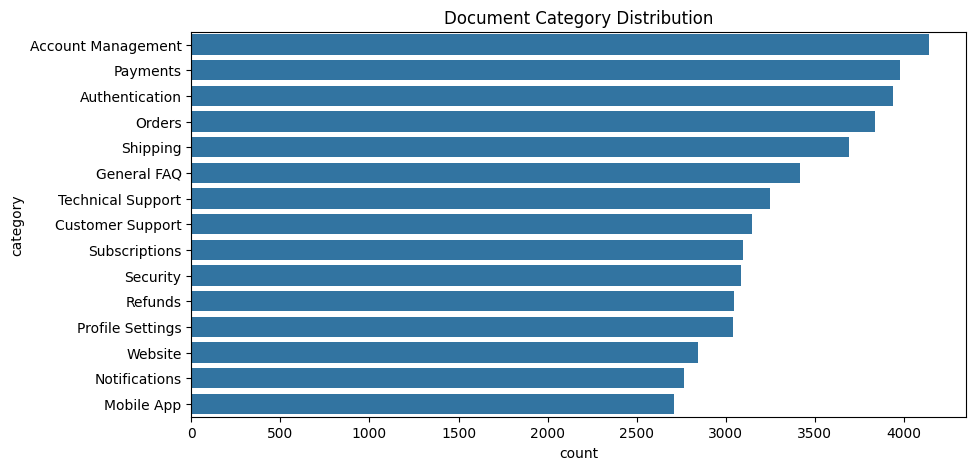

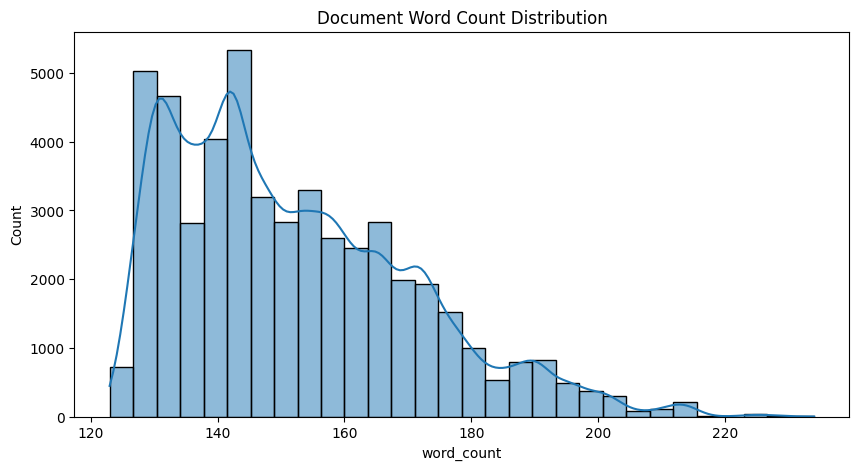

count    50000.000000
mean       151.863420
std         18.891453
min        123.000000
25%        137.000000
50%        148.000000
75%        164.000000
max        234.000000
Name: word_count, dtype: float64


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate content length
df["content_length"] = (
    df["content"].fillna("").str.len()
)

# Calculate word count
df["word_count"] = (
    df["content"].fillna("").str.split().str.len()
)

# Document category distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index
)

plt.title("Document Category Distribution")
plt.show()

# Document word count distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df["word_count"],
    bins=30,
    kde=True
)

plt.title("Document Word Count Distribution")
plt.show()

# Basic statistics
print(df["word_count"].describe())

3 – Text Preprocessing
Your technical assessment specifically mentions:
- Lowercasing.
- Tokenisation.
- Stopword removal.

In [4]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))


def preprocess_text(text):

    if pd.isna(text):
        return ""

    # Lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return tokens


# Apply preprocessing
df["cleaned_content"] = (
    df["content"].apply(preprocess_text)
)

print(df[[
    "content",
    "cleaned_content"
]].head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


                                             content  \
0  If you can no longer use your sign-in password...   
1  Problems with your log in are often caused by ...   
2  You can set up your two-step verification your...   
3  Most issues with your login code clear up afte...   
4  Setting up your authentication app takes only ...   

                                     cleaned_content  
0  [longer, use, sign, password, restore, access,...  
1  [problems, log, often, caused, something, smal...  
2  [set, two, step, verification, without, contac...  
3  [issues, login, code, clear, checks, described...  
4  [setting, authentication, app, takes, minute, ...  


4 – Feature Engineering
Your dataset has five columns. We should decide which columns contribute to semantic search.
My recommendation:
Column	Usage
Document ID	Identification only
Title	Include
Category	Include
Content	Primary text
Keywords	Include

In [5]:
# Handle missing values
text_columns = [
    "title",
    "category",
    "content",
    "keywords"
]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str)


# Create combined document text
df["document_text"] = (
    df["title"] + " " +
    df["category"] + " " +
    df["content"] + " " +
    df["keywords"]
)

print(df[[
    "document_id",
    "document_text"
]].head())

  document_id                                      document_text
0    KB000001  Unable to Access Your Login Password Step by S...
1    KB000002  Login Troubleshooting the Easy Way Authenticat...
2    KB000003  Setting Up Extra Login Step Authentication You...
3    KB000004  Verification Code Troubleshooting Explained Au...
4    KB000005  How to Set Up Your Authentication App the Easy...


Stage 5 – Build TF-IDF Baseline Model

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Convert document text into TF-IDF vectors
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(
    df["document_text"]
)

print("TF-IDF Shape:", tfidf_matrix.shape)

TF-IDF Shape: (50000, 10000)


Create the search function:

In [7]:
def tfidf_search(query, top_k=5):

    query_vector = tfidf.transform([query])

    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = df.iloc[top_indices].copy()

    results["similarity_score"] = scores[top_indices]

    return results[[
        "document_id",
        "title",
        "category",
        "similarity_score"
    ]]

Test:

In [10]:
query = "How can customer data be protected?"

results = tfidf_search(query, top_k=5)

results

,document_id,title,category,similarity_score
22483,KB022484,Your Personal Data Explained in Minutes,Security,0.411187
43298,KB043299,How to Check Your Account Data on iOS,Security,0.407617
22171,KB022172,How Do I View My Personal Data? Quick Guide,Security,0.406758
3951,KB003952,What Your Account Data Means Quick Guide,Account Management,0.406705
43622,KB043623,Understanding Your Personal Data in the App,Security,0.403374


6 – Word Embeddings using FastText
The assessment requires dense word representations using Word2Vec and permits FastText for unseen words.

Here's the distinction:
Model	Purpose
Word2Vec	Learns word representations from context
CBOW	Predicts a target word using surrounding words
Skip-Gram	Predicts surrounding words using a target word
FastText	Learns representations using character n-grams

For our first implementation, I recommend FastText with Skip-Gram because the assessment explicitly considers unseen words.

In [11]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 77.7 MB/s  0:00:00


In [12]:
from gensim.models import FastText

# Prepare tokenized documents
sentences = df["document_text"].apply(
    preprocess_text
).tolist()

# Train FastText
fasttext_model = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    workers=4,
    epochs=30,
    seed=42
)

print("Vocabulary Size:",
      len(fasttext_model.wv))

Vocabulary Size: 733


7 – Generate Document Embeddings
Now we need to convert each complete document into a single numerical vector.

Our FastText model produces word vectors. We can calculate the average of the word vectors to represent a complete document.

In [13]:
def get_document_embedding(tokens, model):

    vectors = [
        model.wv[word]
        for word in tokens
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Generate document embeddings
df["tokens"] = df["document_text"].apply(
    preprocess_text
)

document_embeddings = np.vstack([
    get_document_embedding(tokens, fasttext_model)
    for tokens in df["tokens"]
])

print(
    "Document Embedding Shape:",
    document_embeddings.shape
)

Document Embedding Shape: (50000, 100)


8 – Semantic Similarity using Cosine Similarity
This is the most important functionality of our project.

We need to:
1. Accept a user query.
2. Preprocess the query.
3. Generate its embedding.
4. Compare it against all document embeddings.
5. Calculate cosine similarity.

In [14]:
from sklearn.metrics.pairwise import cosine_similarity


def semantic_search(query, top_k=5):

    # Preprocess query
    query_tokens = preprocess_text(query)

    # Generate query embedding
    query_embedding = get_document_embedding(
        query_tokens,
        fasttext_model
    )

    query_embedding = query_embedding.reshape(1, -1)

    # Calculate cosine similarity
    scores = cosine_similarity(
        query_embedding,
        document_embeddings
    ).flatten()

    # Rank documents
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = df.iloc[top_indices].copy()

    results["similarity_score"] = scores[top_indices]

    return results[[
        "document_id",
        "title",
        "category",
        "content",
        "similarity_score"
    ]]

test

In [15]:
query = "How can an organization secure customer information?"

results = semantic_search(
    query,
    top_k=5
)

print(results)

      document_id                                 title          category  \
31231    KB031232          Activate Help Desk Explained  Customer Support   
31915    KB031916  Activate Customer Service on the Web  Customer Support   
48350    KB048351           Setting Up Help Desk on iOS  Customer Support   
32035    KB032036     First Steps With Help Desk on iOS  Customer Support   
31987    KB031988   Start Using Help Desk for New Users  Customer Support   

                                                 content  similarity_score  
31231  You can set up your customer service yourself ...          0.680821  
31915  This guide walks you through enabling your cus...          0.680528  
48350  You can set up your customer service yourself ...          0.676697  
32035  You can set up your customer service yourself ...          0.673560  
31987  Setting up your customer service takes only a ...          0.672623  


9 – Ranking and User-Controlled Top-K Results
The assessment requires users to specify how many documents they want returned.

We already support that through top_k.

In [16]:
query = "Information security and data protection"

results = semantic_search(
    query,
    top_k=10
)

for _, row in results.iterrows():

    print("Document ID:", row["document_id"])

    print("Title:", row["title"])

    print("Category:", row["category"])

    print(
        "Similarity:",
        round(row["similarity_score"], 4)
    )

    print("-" * 50)

Document ID: KB005558
Title: Steps to Recover Your Deleted Data on Android
Category: Account Management
Similarity: 0.698
--------------------------------------------------
Document ID: KB004630
Title: Regain Access to Your Removed Data FAQ
Category: Account Management
Similarity: 0.6966
--------------------------------------------------
Document ID: KB003846
Title: Regain Access to Your Deleted Data on the Web
Category: Account Management
Similarity: 0.6956
--------------------------------------------------
Document ID: KB005110
Title: Regain Access to Your Removed Data for Business Accounts
Category: Account Management
Similarity: 0.6932
--------------------------------------------------
Document ID: KB005414
Title: How to Reset Your Removed Data the Easy Way
Category: Account Management
Similarity: 0.6922
--------------------------------------------------
Document ID: KB004774
Title: Reset Your Deleted Data
Category: Account Management
Similarity: 0.6916
----------------------------

10 – Model Evaluation
Important for your technical assessment
The assessment evaluates retrieval quality, robustness, generalisation, clarity and code quality. NLP_P5_Technical_Assessment_Semantic_Search.pdf


We should compare two approaches:
1. TF-IDF baseline.
2. FastText semantic search.

But there is one important point: similarity scores alone cannot tell us whether the retrieved documents are actually relevant.

We need a small set of test queries with manually identified relevant document IDs. These are called relevance judgments or ground-truth labels.
Example evaluation queries
Use these as initial test queries, adjusting them to the actual subject matter of your dataset.
Query	What it tests
How can customer information be protected?	Semantic meaning
What are the responsibilities of an organisation?	Concept understanding
Explain data privacy requirements	Related terminology
How should sensitive information be handled?	Context
What happens when security rules are violated?	Different wording
How can access to confidential records be controlled?	Related concepts

Evaluation metrics
Metric	What it measures
Precision@K	How many retrieved documents are relevant?
Recall@K	How many relevant documents were retrieved?
MRR	How high the first relevant document appears
nDCG@K	How well relevant documents are ordered

Python evaluation code
First, manually create relevance judgments using your existing document IDs.

In [17]:
# Example only: replace these IDs with
# document IDs from your actual dataset.

relevance = {
    "How can customer information be protected?": [
        105, 108, 112
    ],

    "Explain data privacy requirements": [
        108, 115
    ]
}

Evaluation functions:

In [18]:
def precision_at_k(retrieved, relevant, k):

    retrieved_k = retrieved[:k]

    if not retrieved_k:
        return 0

    hits = sum(
        doc_id in relevant
        for doc_id in retrieved_k
    )

    return hits / k


def recall_at_k(retrieved, relevant, k):

    if not relevant:
        return 0

    retrieved_k = retrieved[:k]

    hits = sum(
        doc_id in relevant
        for doc_id in retrieved_k
    )

    return hits / len(relevant)


def reciprocal_rank(retrieved, relevant):

    for rank, doc_id in enumerate(retrieved, start=1):

        if doc_id in relevant:
            return 1 / rank

    return 0

Run evaluation:

In [21]:
def evaluate_model(search_function, relevance, k=5):

    scores = []

    for query, relevant_docs in relevance.items():

        results = search_function(query, top_k=k)

        retrieved = results["document_id"].tolist()

        scores.append({
            "Precision@K": precision_at_k(
                retrieved, relevant_docs, k
            ),

            "Recall@K": recall_at_k(
                retrieved, relevant_docs, k
            ),

            "MRR": reciprocal_rank(
                retrieved, relevant_docs
            )
        })

    return pd.DataFrame(scores).mean()


# Evaluate TF-IDF
tfidf_metrics = evaluate_model(
    tfidf_search,
    relevance
)

# Evaluate semantic search
semantic_metrics = evaluate_model(
    semantic_search,
    relevance
)

comparison = pd.DataFrame({
    "TF-IDF": tfidf_metrics,
    "FastText": semantic_metrics
})

comparison

,TF-IDF,FastText
Precision@K,0.0,0.0
Recall@K,0.0,0.0
MRR,0.0,0.0
